## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Sam Nieto Beltran]

**Date:** [10/13/26]

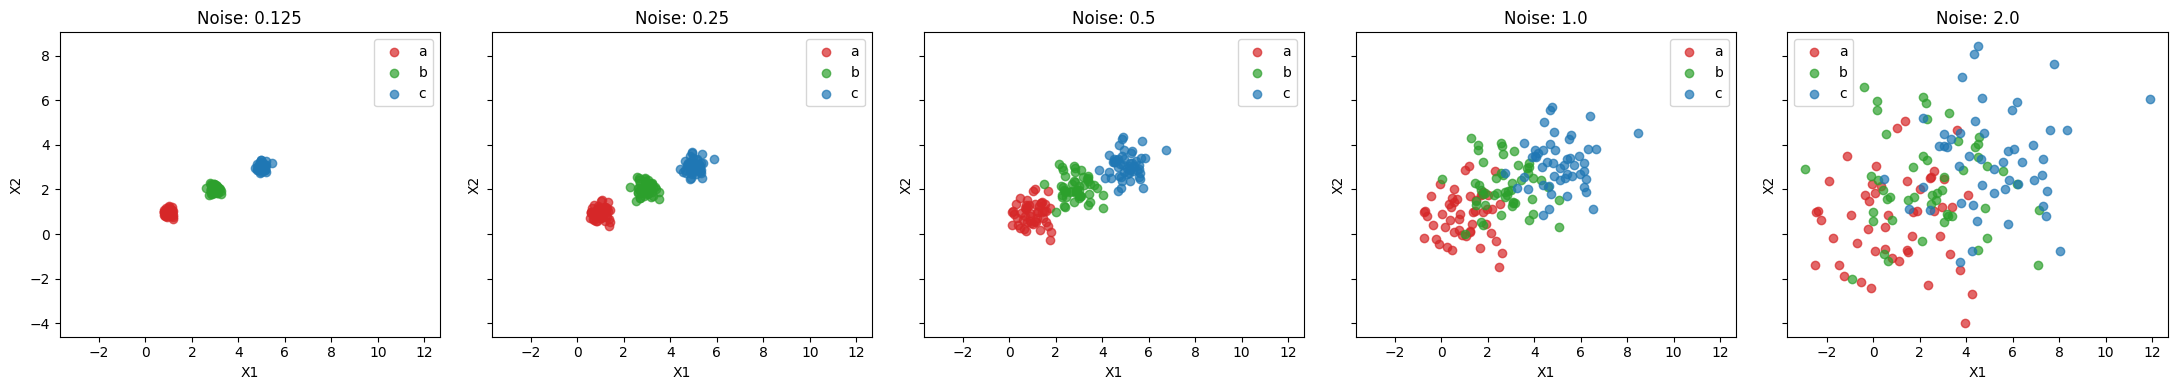

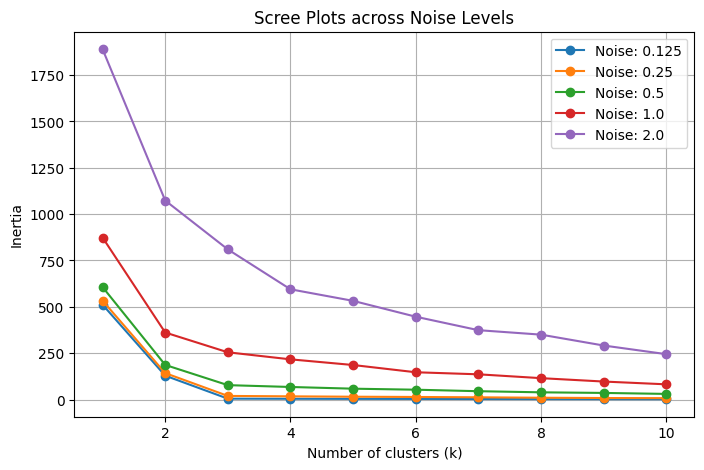

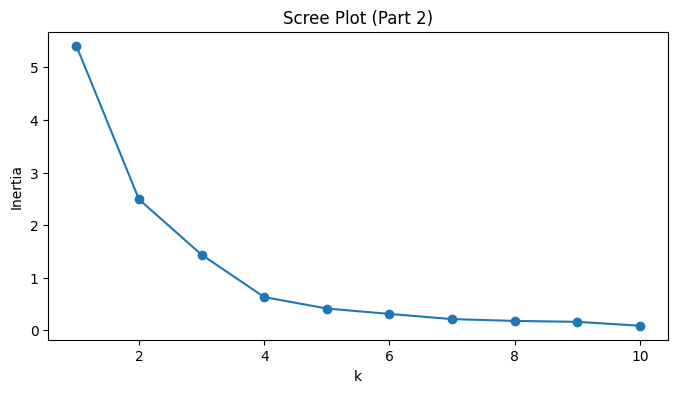

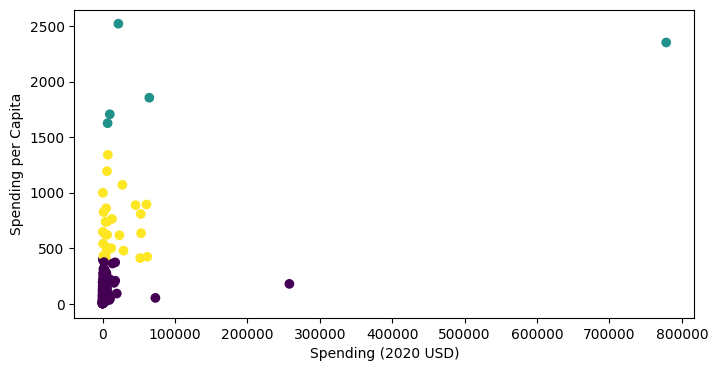

--- Part 2 Describe Table ---
           Spending (2020 USD)                                             \
                         count           mean            std          min   
cluster_p2                                                                  
0                        117.0    4934.990482   24788.961392     8.622460   
1                          5.0  176338.356708  337349.084932  6941.042345   
2                         26.0   18756.499433   21418.276892   405.790494   

                                                                    \
                    25%           50%           75%            max   
cluster_p2                                                           
0            147.873732    483.415023   2567.917819  257973.429834   
1           9978.571429  21816.569767  64558.400000  778397.200000   
2           4141.399749   6330.477850  28516.230742   61712.537169   

           Spending per Capita                                        \
              

In [2]:
# Your Phase 1 solution to the problem goes here.
# Q1
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans


# function provided in Q1
def createData(noise, N=50):
  np.random.seed(100)
  X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
  X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
  X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])

  gdf1 = pd.DataFrame({'X1': X1[0, :], 'X2': X1[1, :], 'group': 'a'})
  gdf2 = pd.DataFrame({'X1': X2[0, :], 'X2': X2[1, :], 'group': 'b'})
  gdf3 = pd.DataFrame({'X1': X3[0, :], 'X2': X3[1, :], 'group': 'c'})
  df = pd.concat([gdf1, gdf2, gdf3], axis=0)
  return df


datasets = {
    '0.125': createData(0.125),
    '0.25': createData(0.25),
    '0.5': createData(0.5),
    '1.0': createData(1.0),
    '2.0': createData(2.0),
}

# 2. Scatterplots by group for each dataset
# Q2: As noise increases, the clusters become progressivly more overlapped and lose their visual cohesiveness.
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharex=True, sharey=True)
for ax, (noise_val, df) in zip(axes, datasets.items()):
  for group, color in zip(['a', 'b', 'c'], ['tab:red', 'tab:green', 'tab:blue']):
    subset = df[df['group'] == group]
    ax.scatter(subset['X1'], subset['X2'], label=group, alpha=0.7, c=color)
  ax.set_title(f'Noise: {noise_val}')
  ax.set_xlabel('X1')
  ax.set_ylabel('X2')
  ax.legend()
plt.tight_layout()
plt.show()

# 3 & 4. Scree plots for each dataset on a single canvas
# Q3: Higher noise levels smooth out the scree curve, making the optimal "elbow" less pronounced and harder to definitively select.
# Q4: The elbow is where adding more groups stops being helpful because you're just cutting up random noise instead of finding real patterns.
fig, ax = plt.subplots(figsize=(8, 5))
k_range = range(1, 11)

for noise_val, df in datasets.items():
  inertias = []
  X = df[['X1', 'X2']].values
  for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init='auto', random_state=42)
    kmeans.fit(X)
    inertias.append(kmeans.inertia_)
  ax.plot(k_range, inertias, marker='o', label=f'Noise: {noise_val}')

ax.set_title('Scree Plots across Noise Levels')
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Inertia')
ax.legend()
ax.grid(True)
plt.show()

#Q2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

# 1.
# Q1: Is any further cleaning required?
# Beyond dropping missing values, features require scaling due to the massive right-skewness of absolute financial values.
url = 'https://raw.githubusercontent.com/samnietobeltran-jpg/A04-clustering/main/data/SIPRI%20Military%20Expenditure%20Database.csv'
df = pd.read_csv(url)
df_2020 = df[df['Year'] == 2020].dropna()

scaler = MinMaxScaler()

# 2. Part 2: Spending (2020 USD) & Spending per Capita
# Q2: What do you see? Where is the US? Any patterns?
# Absolute spending and per-capita metrics isolate the United States in its own cluster due to extreme total expenditures, while most nations group into a low-spending majority.
vars_p2 = ['Spending (2020 USD)', 'Spending per Capita']
X_p2 = scaler.fit_transform(df_2020[vars_p2])

inertias = []
for k in range(1, 11):
  km = KMeans(n_clusters=k, n_init='auto', random_state=42).fit(X_p2)
  inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), inertias, marker='o')
plt.title('Scree Plot (Part 2)')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.show()

optimal_k = 3
km_p2 = KMeans(n_clusters=optimal_k, n_init='auto', random_state=42)
df_2020['cluster_p2'] = km_p2.fit_predict(X_p2)

plt.figure(figsize=(8, 4))
plt.scatter(
    df_2020['Spending (2020 USD)'],
    df_2020['Spending per Capita'],
    c=df_2020['cluster_p2'],
    cmap='viridis',
)
plt.xlabel('Spending (2020 USD)')
plt.ylabel('Spending per Capita')
plt.show()

print('--- Part 2 Describe Table ---')
print(df_2020.groupby('cluster_p2')[vars_p2].describe())


# 3.
# Q3: How do your results compare to part 2?
# Looking at percentages instead of total dollars changes the groups by focusing on how much a country prioritizes defense compared to its overall budget rather than its sheer wealth.
vars_p3 = ['Percent of Government Spending', 'Percent of GDP']
X_p3 = scaler.fit_transform(df_2020[vars_p3])
df_2020['cluster_p3'] = KMeans(
    n_clusters=3, n_init='auto', random_state=42
).fit_predict(X_p3)

print('--- Part 3 Describe Table ---')
print(df_2020.groupby('cluster_p3')[vars_p3].describe())


# 4.
# Q4: How do your results compare to the previous two parts?
# Combining all four variables produces a hybrid model balancing absolute financial scale with relative budget allocation.
vars_all = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP',
]
X_all = scaler.fit_transform(df_2020[vars_all])
df_2020['cluster_all'] = KMeans(
    n_clusters=3, n_init='auto', random_state=42
).fit_predict(X_all)

print('--- Part 4 Describe Table ---')
print(df_2020.groupby('cluster_all')[vars_all].describe())

# Q5: Did the k-MC algorithm find any useful patterns?
# Yes, the algorithm effectively highlights useful global spending patterns by puttimg countries into distinct strategic archetypes.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]